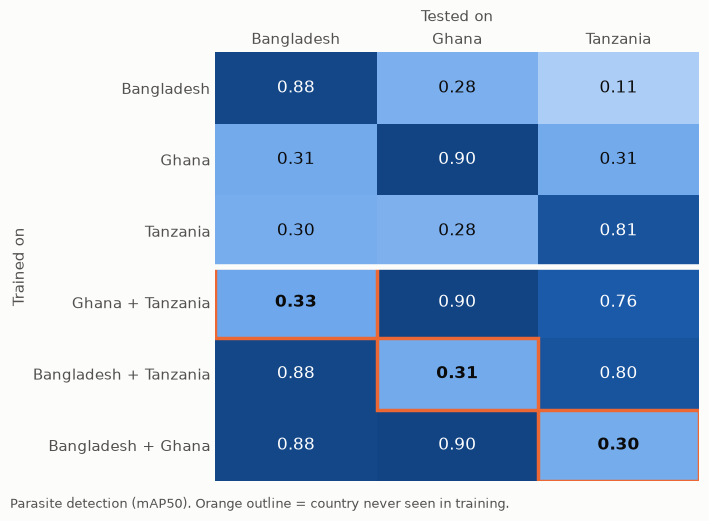

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
R = Path("../results")
BLUE, ORANGE, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

cs = pd.read_csv(R / "cross_site_detection.csv")
grid = cs.pivot(index="model", columns="test_site", values="par_mAP50").loc[
    ["A_bd", "B_gh", "C_tz", "D_gh_tz", "E_bd_tz", "F_bd_gh"], ["bd", "gh", "tz"]]
rows = ["Bangladesh", "Ghana", "Tanzania", "Ghana + Tanzania", "Bangladesh + Tanzania", "Bangladesh + Ghana"]
cols = ["Bangladesh", "Ghana", "Tanzania"]
unseen = {(3, 0), (4, 1), (5, 2)}                     

cmap = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.2, 5.2))
ax.imshow(grid.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
for i in range(6):
    for j in range(3):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=12,
                color="white" if v > 0.55 else INK, fontweight="bold" if (i, j) in unseen else "normal")
        if (i, j) in unseen:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=ORANGE, lw=2.5))
ax.set_xticks(range(3), cols); ax.set_yticks(range(6), rows)
ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
ax.set_xlabel("Tested on", labelpad=8); ax.set_ylabel("Trained on")
ax.axhline(2.5, color=SURF, lw=4)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
fig.text(0.02, 0.01, "Parasite detection (mAP50). Orange outline = country never seen in training.", color=INK2, fontsize=9.5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(R / "fig1_cross_country_grid.png", dpi=200, facecolor=SURF); plt.show()

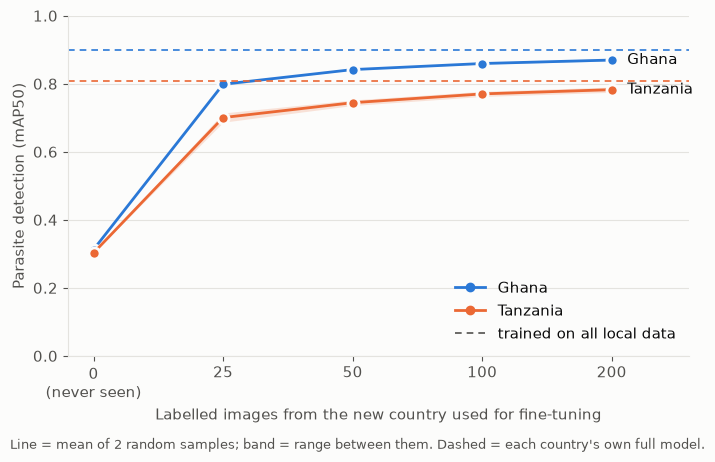

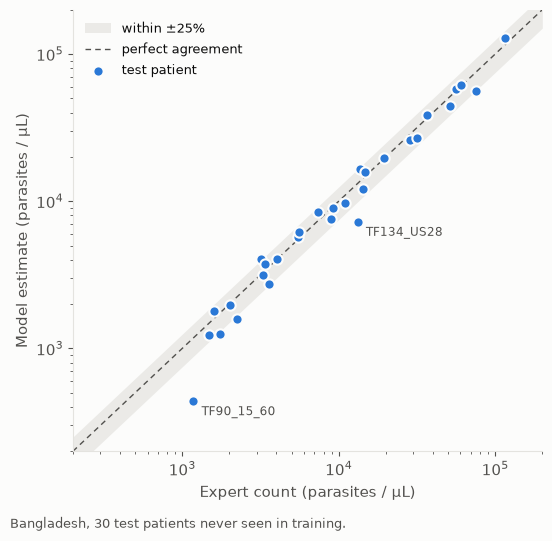

In [2]:
fs = pd.read_csv(R / "few_shot_results.csv")
home_score = {"gh": grid.loc["B_gh", "gh"], "tz": grid.loc["C_tz", "tz"]}
ks = [0, 25, 50, 100, 200]; x = np.arange(len(ks))
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for site, colour, label in [("gh", BLUE, "Ghana"), ("tz", ORANGE, "Tanzania")]:
    s = fs[fs.site == site].groupby("k").par_mAP50.agg(["mean", "min", "max"]).reindex(ks)
    ax.fill_between(x, s["min"], s["max"], color=colour, alpha=0.18, lw=0)
    ax.plot(x, s["mean"], color=colour, lw=2, marker="o", ms=8, mec=SURF, mew=2)
    ax.axhline(home_score[site], color=colour, lw=1.2, ls=(0, (4, 3)))
    ax.text(x[-1] + 0.12, s["mean"].iloc[-1], label, color=INK, va="center", fontsize=11)
ax.set_xticks(x, ["0\n(never seen)", "25", "50", "100", "200"])
ax.set_xlim(-0.2, len(ks) - 0.4); ax.set_ylim(0, 1)
ax.set_xlabel("Labelled images from the new country used for fine-tuning")
ax.set_ylabel("Parasite detection (mAP50)")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(handles=[plt.Line2D([], [], color=BLUE, lw=2, marker="o", label="Ghana"),
                   plt.Line2D([], [], color=ORANGE, lw=2, marker="o", label="Tanzania"),
                   plt.Line2D([], [], color=INK2, lw=1.2, ls=(0, (4, 3)), label="trained on all local data")],
          frameon=False, loc="lower right")
fig.text(0.02, 0.01, "Line = mean of 2 random samples; band = range between them. Dashed = each country's own full model.",
         color=INK2, fontsize=9.5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(R / "fig2_local_images.png", dpi=200, facecolor=SURF); plt.show()

bd = pd.read_csv(R / "nlm_test_patient_density.csv")
fig, ax = plt.subplots(figsize=(5.6, 5.4))
lim = (200, 2e5); line = np.array(lim)
ax.fill_between(line, line * 0.75, line * 1.25, color=GRID, alpha=0.7, lw=0, label="within ±25%")
ax.plot(line, line, color=INK2, lw=1, ls=(0, (4, 3)), label="perfect agreement")
ax.scatter(bd.density_per_uL, bd.pred_density, s=55, color=BLUE, edgecolor=SURF, linewidth=1.5, zorder=3, label="test patient")
for _, r in bd[bd.ratio < 0.6].iterrows():
    ax.annotate(r.patient, (r.density_per_uL, r.pred_density), xytext=(6, -10), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Expert count (parasites / µL)"); ax.set_ylabel("Model estimate (parasites / µL)")
ax.legend(frameon=False, loc="upper left", fontsize=9.5)
fig.text(0.02, 0.01, "Bangladesh, 30 test patients never seen in training.", color=INK2, fontsize=9.5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(R / "fig3_density_agreement.png", dpi=200, facecolor=SURF); plt.show()